In [118]:
# Add relevant Jupyter notebook extensions 
%matplotlib inline

# Automatically reload all modified python files before executing code
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [119]:
import sys
from pathlib import Path

# Add the project root folder (folder/) to sys.path so Python finds uuv_mission
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

#removed print statements to avoid cluttering the notebook output

# Simulate closed-loop
### UUV mission: closed loop controller demonstration

Loads cave mission, regulates submarine's depth with PD controller, and plots trajectory against both reference and cave walls. 

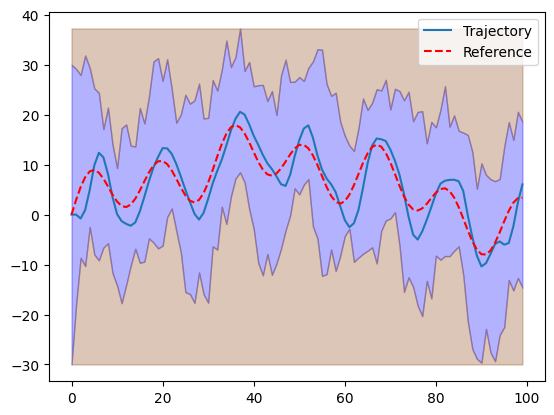

In [120]:
# Import relevant modules
import numpy as np
from uuv_mission.dynamic import Submarine, Mission, ClosedLoop
from uuv_mission.control import Controller

# Create the plant and  PD controller
sub = Submarine()

# Instantiate your controller
controller = Controller()
# Connect the plant and controller in a closed-loop system
closed_loop = ClosedLoop(sub, controller)
mission = Mission.from_csv("../data/mission.csv")
 

# Simulate the closed-loop system with random disturbances and plot the results
trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)